# Pre-entrega 3: Clasificador supervisado con TF-IDF

**Data Science III: NLP & Deep Learning aplicado a Ciencia de Datos**
**Alumno:** Lucas Nahuel Julian
**Dataset:** AG News

### Objetivo
Armar un pipeline de clasificación supervisada con Machine Learning: se retoma el preprocesamiento
de la pre-entrega anterior, se vectoriza el texto con TfidfVectorizer y se entrena un clasificador de
referencia. Al final se evalúa con classification_report y matriz de confusión.

### Estructura del notebook
1. Carga de librerías
2. Carga del dataset (train y test)
3. Preprocesamiento (funciones del Módulo 2)
4. Vectorización TF-IDF: prueba de max_features y ngram_range
5. Elección del modelo
6. Entrenamiento final y evaluación sobre test
7. Prueba con noticias nuevas
8. Conclusiones

## **1. Carga de librerías**

In [ ]:
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

import spacy
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

## **2. Carga del dataset**

Se usan los dos archivos que ya vienen separados (ag_news_train.csv y ag_news_test.csv). Los splits se mantienen como vienen: el test no se toca hasta la evaluación final.

In [3]:
# Cambiá a "bbc_news" si preferís artículos largos.
DATASET = "ag_news"            # opciones: "ag_news" | "bbc_news"
BASE = Path("../data")  # carpeta donde está este script


def cargar(dataset: str = DATASET):
    """Devuelve (train_df, test_df) con columnas: text, label."""
    tr = pd.read_csv(BASE / f"{dataset}_train.csv")
    te = pd.read_csv(BASE / f"{dataset}_test.csv")
    return tr, te


if __name__ == "__main__":
    train_df, test_df = cargar()
    print(f"Dataset: {DATASET}")
    print(f"Train: {train_df.shape} | Test: {test_df.shape}")
    print("Clases:", sorted(train_df['label'].unique()))
    print(train_df.head())


print(f"Train: {train_df.shape} | Test: {test_df.shape}")
print("Clases:", sorted(train_df['label'].unique()))
train_df.head()

Dataset: ag_news
Train: (8000, 2) | Test: (2000, 2)
Clases: ['Business', 'Sci_Tech', 'Sports', 'World']
                                                text     label
0  Red Hat Appoints New CFO. September 2, 2004 --...  Sci_Tech
1  Sprint, SBC In Hotspot Roaming Deal. Sprint an...  Sci_Tech
2  Radio Outage Grounds West Coast Flights. Airpo...  Business
3  Hollywood lawsuits to strike Net pirates. Holl...  Sci_Tech
4  Custis Takes Control. Family and Tony Robbins ...    Sports
Train: (8000, 2) | Test: (2000, 2)
Clases: ['Business', 'Sci_Tech', 'Sports', 'World']


,text,label
0,"Red Hat Appoints New CFO. September 2, 2004 --...",Sci_Tech
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",Sci_Tech
2,Radio Outage Grounds West Coast Flights. Airpo...,Business
3,Hollywood lawsuits to strike Net pirates. Holl...,Sci_Tech
4,Custis Takes Control. Family and Tony Robbins ...,Sports


In [ ]:
# Balance de clases en los dos splits
pd.DataFrame({
    'train': train_df['label'].value_counts(),
    'test': test_df['label'].value_counts()
})

,train,test
label,,
Business,2000,500
Sci_Tech,2000,500
Sports,2000,500
World,2000,500


Tenemos 8.000 noticias de entrenamiento y 2.000 de test, con las 4 clases balanceadas (2.000 y 500 por clase).

## **3. Preprocesamiento**

Se reutilizan las funciones de la pre-entrega anterior sin cambios:
- clean_text(): limpieza con Regex (apóstrofo mal codificado, HTML, URLs, emails, dominios, firmas de
  agencias, números) y normalización (minúsculas y espacios).
- preprocess_text(): limpia, lematiza con SpaCy y saca puntuación y stop-words, conservando las negaciones.

In [6]:
def clean_text(text):

    text = str(text)

    # Apóstrofo mal codificado: "Europe #39;s" -> "Europe's"
    text = re.sub(r'\s?#39;', "'", text)

    # HTML escapado: convertimos &lt; y &gt; en < y > para poder borrar las etiquetas
    text = text.replace('&lt;', '<').replace('&gt;', '>')

    # Etiquetas HTML (también las que quedaron cortadas al final del texto)
    text = re.sub(r'<[^>]*>?', ' ', text)

    # Entidades HTML, ahora con límite de palabra (\b) para no cortar palabras
    text = re.sub(r'&amp;|\bquot;|\bamp;|\blt;|\bgt;|#\d+;', ' ', text)

    # URLs, emails y dominios (redhat.com, washingtonpost.com)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b', ' ', text)
    text = re.sub(r'\b\w+\.(com|net|org)\b', ' ', text)

    # Texto fijo de Reuters junto a las empresas: "(GE.N: Quote, Profile, Research)"
    text = re.sub(r'\([^)]*Quote, Profile, Research\)', ' ', text)

    # Firmas de agencias de noticias: "(Reuters)", "(AP)", "Reuters - "
    text = re.sub(r'\((Reuters|AP|AFP|CP|Canadian Press|Sports Network)\)', ' ', text)
    text = re.sub(r'\b(Reuters|AP|AFP) - ', ' ', text)

    # "U.S." -> "USA" para que no se pierda como letras sueltas
    text = text.replace('U.S.', 'USA')

    # Números
    text = re.sub(r'\d+', ' ', text)

    # Minúsculas
    text = text.lower()

    # Espacios múltiples
    text = re.sub(r'\s+', ' ', text)

    return text.strip()

Las stop-words son las mismas de la pre-entrega 2: la lista de SpaCy más las palabras de ruido (HTML, dominios, agencias) y los días de la semana, sacando las negaciones.

In [7]:
# Palabras de ruido detectadas en el EDA del Módulo 2
RUIDO = {'www', 'http', 'https', 'com', 'net', 'org', 'afp', 'fullquote', 'href', 'quickinfo', 'aspx',
         'ticker', 'ap', 'gt', 'lt', '39', 's', 'u', 'quot', 'quote', 'co', 'size', 'font', 'verdana',
         'serif', 'sans', 'arial', 'helvetica', 'ms', 'reuters', "'s"}

NEGACIONES = {'no', 'not', 'never', 'nor', 'without', 'against', 'none', 'nothing', "n't"}

DIAS = {'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday',
        'yesterday', 'today'}

STOPWORDS_FINAL = (nlp.Defaults.stop_words | RUIDO | DIAS) - NEGACIONES

print(f"Stop-words finales: {len(STOPWORDS_FINAL)}")

Stop-words finales: 356


In [8]:
def preprocess_text(text):

    text = clean_text(text)

    doc = nlp(text)

    tokens = []

    for token in doc:

        if token.is_punct:
            continue

        if token.is_space:
            continue

        lema = token.lemma_.lower()

        # "didn't" -> SpaCy separa "did" + "n't"; guardamos la negación como "not"
        if lema == "n't":
            lema = "not"

        if lema in STOPWORDS_FINAL:
            continue

        if len(lema) < 2:
            continue

        tokens.append(lema)

    return " ".join(tokens)

Se aplica la misma función a train y a test. El preprocesamiento no aprende nada de los datos (no hay fit).

In [9]:
train_df["text_preprocessed"] = train_df["text"].apply(preprocess_text)
test_df["text_preprocessed"] = test_df["text"].apply(preprocess_text)

train_df[["text", "text_preprocessed", "label"]].head()

,text,text_preprocessed,label
0,"Red Hat Appoints New CFO. September 2, 2004 --...",red hat appoint new cfo september web host ind...,Sci_Tech
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",sprint sbc hotspot roam deal sprint sbc commun...,Sci_Tech
2,Radio Outage Grounds West Coast Flights. Airpo...,radio outage ground west coast flight airport ...,Business
3,Hollywood lawsuits to strike Net pirates. Holl...,hollywood lawsuit strike pirate hollywood stud...,Sci_Tech
4,Custis Takes Control. Family and Tony Robbins ...,custis control family tony robbin mature mold ...,Sports


In [ ]:
# Control después del preprocesamiento
print("Vacíos en train:", (train_df["text_preprocessed"].str.strip() == "").sum())
print("Vacíos en test:", (test_df["text_preprocessed"].str.strip() == "").sum())

Vacíos en train: 0
Vacíos en test: 0


In [11]:
X_train = train_df["text_preprocessed"]
y_train = train_df["label"]

X_test = test_df["text_preprocessed"]
y_test = test_df["label"]

## **4. Vectorización TF-IDF**

TfidfVectorizer convierte cada noticia en un vector donde cada posición es una palabra o un n-grama del
vocabulario, con un peso que es más alto cuando la palabra aparece mucho en esa noticia pero poco en el resto.

El vectorizador se ajusta (fit_transform) solo con train. Para elegir los
parámetros uso validación cruzada dentro de train, metiendo el vectorizador y el modelo en un
pipeline. Así en cada fold el vocabulario y los IDF se calculan solo con la parte de entrenamiento de
ese fold. El test queda guardado para el final.

Parámetros de prueba:
- max_features: tamaño máximo del vocabulario (5000, 10000, 20000 o sin límite).
- ngram_range: solo unigramas (1, 1) o unigramas + bigramas (1, 2).

Para comparar los parámetros dejo fijo un modelo (Regresión Logística) y uso la métrica F1 macro.

In [ ]:
# Reviso qué tan grande es el vocabulario completo con cada ngram_range en el train.
for ngram in [(1, 1), (1, 2)]:
    vec = TfidfVectorizer(ngram_range=ngram)
    vec.fit(X_train)
    print(f"ngram_range={ngram}: {len(vec.vocabulary_):,} términos")

ngram_range=(1, 1): 16,823 términos
ngram_range=(1, 2): 146,828 términos


Con bigramas el vocabulario se multiplica (la mayoría de los bigramas aparece una sola vez), por eso tiene
sentido limitarlo con max_features.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados = []

for ngram in [(1, 1), (1, 2)]:
    for max_feat in [5000, 10000, 20000, None]:

        pipe = Pipeline([
            ("tfidf", TfidfVectorizer(ngram_range=ngram, max_features=max_feat, sublinear_tf=True)),
            ("modelo", LogisticRegression(max_iter=1000))
        ])

        scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro")

        resultados.append({
            "ngram_range": str(ngram),
            "max_features": max_feat if max_feat else "sin límite",
            "f1_macro_cv": scores.mean(),
            "desvio": scores.std()
        })

resultados_tfidf = pd.DataFrame(resultados).sort_values("f1_macro_cv", ascending=False)
resultados_tfidf.round(4)

,ngram_range,max_features,f1_macro_cv,desvio
6,"(1, 2)",20000,0.8850,0.0075
5,"(1, 2)",10000,0.8838,0.0081
3,"(1, 1)",sin límite,0.8837,0.0101
2,"(1, 1)",20000,0.8837,0.0101
1,"(1, 1)",10000,0.8827,0.0103
7,"(1, 2)",sin límite,0.8826,0.0087
4,"(1, 2)",5000,0.8826,0.0081
0,"(1, 1)",5000,0.8825,0.0097


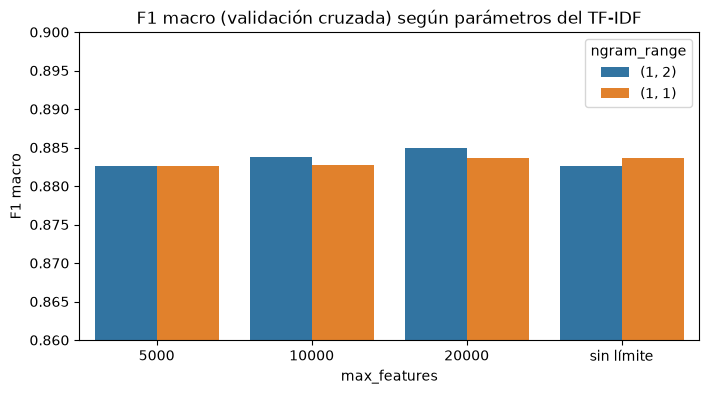

In [14]:
plt.figure(figsize=(8, 4))

sns.barplot(data=resultados_tfidf, x="max_features", y="f1_macro_cv", hue="ngram_range",
            order=[5000, 10000, 20000, "sin límite"])

plt.ylim(0.86, 0.90)
plt.title("F1 macro (validación cruzada) según parámetros del TF-IDF")
plt.ylabel("F1 macro")
plt.xlabel("max_features")
plt.show()

**Observaciones:**
- Todas las combinaciones quedan muy cerca (F1 entre 0,882 y 0,885) y las diferencias son menores que el
  desvío entre folds. Es esperable: las noticias son cortas y las palabras que definen la categoría ya están
  entre los primeros miles de términos del vocabulario.
- Con bigramas sin límite el resultado no mejora: el vocabulario pasa a casi 147000 términos y la mayoría
  aparece una sola vez, o sea que agrega columnas que no aportan. Por eso max_features es importante cuando
  se usan bigramas.
- Elijo ngram_range=(1, 2) con max_features=10000: la diferencia con la mejor combinación (20000
  términos) es de 0,001, y usa la mitad del vocabulario. Los bigramas permiten capturar expresiones como
  oil price, prime minister o red sox que como palabras sueltas pierden sentido.
- sublinear_tf= para que una palabra repetida varias veces en la misma noticia no pese de más.

## **5. Elección del modelo**

Con el vectorizador elegido comparo los tres clasificadores, también con validación cruzada sobre train.

In [15]:
TFIDF_PARAMS = dict(ngram_range=(1, 2), max_features=10000, sublinear_tf=True)

modelos = {
    "Naive Bayes (MultinomialNB)": MultinomialNB(),
    "SVM lineal (LinearSVC)": LinearSVC(),
    "Regresión Logística": LogisticRegression(max_iter=1000),
}

comparacion = []

for nombre, modelo in modelos.items():

    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
        ("modelo", modelo)
    ])

    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro")
    comparacion.append({"modelo": nombre, "f1_macro_cv": scores.mean(), "desvio": scores.std()})

pd.DataFrame(comparacion).sort_values("f1_macro_cv", ascending=False).round(4)

,modelo,f1_macro_cv,desvio
0,Naive Bayes (MultinomialNB),0.8889,0.0060
2,Regresión Logística,0.8838,0.0081
1,SVM lineal (LinearSVC),0.8826,0.0084


Los tres modelos dan resultados parecidos, pero Naive Bayes obtiene el mejor F1 macro y
además el desvío más bajo entre folds. Me quedo con este modelo porque:
- Es el que mejor resultado dio en la validación cruzada sobre train.
- Trabaja directamente con la frecuencia de cada palabra por clase.
- Casi no tiene hiperparámetros.
- Devuelve probabilidades por clase.

## **6. Entrenamiento final y evaluación sobre test**

fit_transform del vectorizador solo sobre train y transform sobre test.

In [16]:
tfidf = TfidfVectorizer(**TFIDF_PARAMS)

# fit solo con train -> el vocabulario y los IDF salen únicamente del set de entrenamiento
X_train_tfidf = tfidf.fit_transform(X_train)

# en test solo transform: las palabras que no estén en el vocabulario de train se ignoran
X_test_tfidf = tfidf.transform(X_test)

print("Matriz train:", X_train_tfidf.shape)
print("Matriz test:", X_test_tfidf.shape)
print(f"Porcentaje de valores distintos de cero (train): {X_train_tfidf.nnz / np.prod(X_train_tfidf.shape) * 100:.2f}%")

Matriz train: (8000, 10000)
Matriz test: (2000, 10000)
Porcentaje de valores distintos de cero (train): 0.20%


La matriz es muy esparsa (casi todos los valores son cero), por eso scikit-learn la guarda en formato
esparso y no como una tabla común.

In [17]:
modelo = MultinomialNB()
modelo.fit(X_train_tfidf, y_train)

y_pred_train = modelo.predict(X_train_tfidf)
y_pred = modelo.predict(X_test_tfidf)

print(f"Accuracy train: {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Accuracy test:  {accuracy_score(y_test, y_pred):.4f}")

Accuracy train: 0.9269
Accuracy test:  0.8960


La accuracy en test (aprox. 0,90) es parecida a la de la validación cruzada (aprox. 0,89), así que el resultado sobre
datos nuevos es consistente con lo que se esperaba. La diferencia con train (aprox. 0,93) es chica: no hay un
overfitting fuerte.

### Reporte de clasificación

In [18]:
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

    Business      0.839     0.862     0.850       500
    Sci_Tech      0.873     0.878     0.875       500
      Sports      0.953     0.966     0.959       500
       World      0.922     0.878     0.900       500

    accuracy                          0.896      2000
   macro avg      0.897     0.896     0.896      2000
weighted avg      0.897     0.896     0.896      2000



### Matriz de confusión

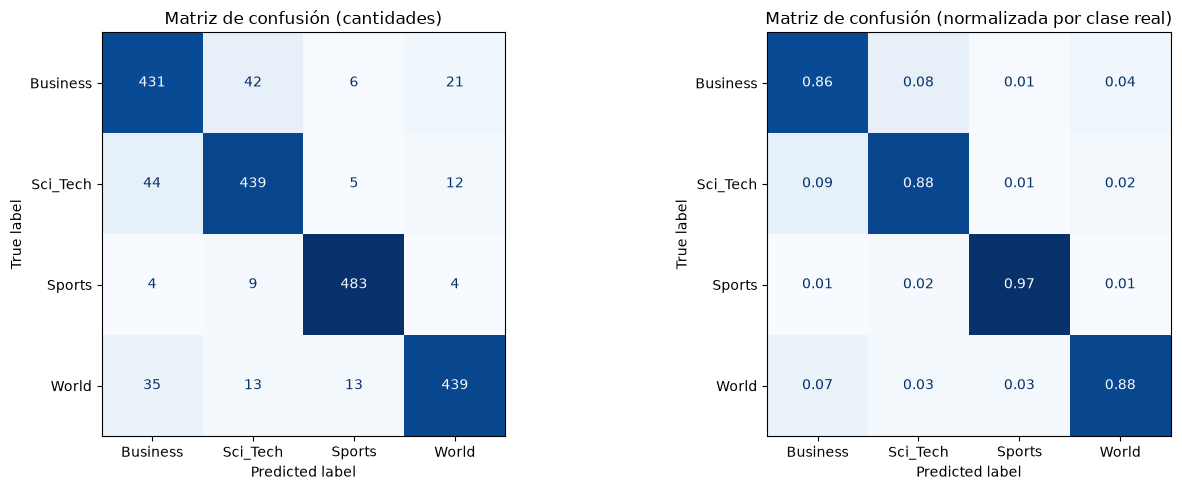

In [19]:
clases = modelo.classes_

cm = confusion_matrix(y_test, y_pred, labels=clases)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Cantidades
ConfusionMatrixDisplay(cm, display_labels=clases).plot(ax=axs[0], cmap="Blues", colorbar=False)
axs[0].set_title("Matriz de confusión (cantidades)")

# Normalizada por fila: qué porcentaje de cada clase real se predijo como cada clase
cm_norm = confusion_matrix(y_test, y_pred, labels=clases, normalize="true")
ConfusionMatrixDisplay(cm_norm, display_labels=clases).plot(ax=axs[1], cmap="Blues", colorbar=False, values_format=".2f")
axs[1].set_title("Matriz de confusión (normalizada por clase real)")

plt.tight_layout()
plt.savefig("matriz_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
# Errores más frecuentes (clase real -> clase predicha)
errores = pd.DataFrame({"real": y_test, "predicha": y_pred})
errores = errores[errores["real"] != errores["predicha"]]

errores.value_counts().head(6)

real      predicha
Sci_Tech  Business    44
Business  Sci_Tech    42
World     Business    35
Business  World       21
World     Sports      13
          Sci_Tech    13
Name: count, dtype: int64

In [21]:
# Algunos ejemplos mal clasificados para entender por qué se equivoca
mal = test_df.loc[errores.index].copy()
mal["predicha"] = errores["predicha"]

for _, fila in mal.sample(5, random_state=1).iterrows():
    print(f"REAL: {fila['label']} | PREDICHA: {fila['predicha']}")
    print(fila["text"][:250])
    print("-" * 80)

REAL: World | PREDICHA: Sci_Tech
Toshiba claims Hollywood backing in war for next DVD standard (AFP). AFP - Toshiba said four major Hollywood studios had thrown their crucial weight behind High Definition DVD (HD-DVD), one of two disc formats contending to be the standard in next-ge
--------------------------------------------------------------------------------
REAL: Business | PREDICHA: Sci_Tech
Retailers Looking to Move Plasma TV's (AP). AP - Hanging stockings by the chimney with care? Retailers hope that St. Nicholas soon will be there #151; to hang a 42-inch plasma-screen TV.
--------------------------------------------------------------------------------
REAL: World | PREDICHA: Business
US economic growth slips to 2.8. Annual US economic growth fell to 2.8 in the second quarter of 2004, marking a slowdown from the 3 estimated a month ago.
--------------------------------------------------------------------------------
REAL: Sci_Tech | PREDICHA: Business
Fujitsu Siemens profit gro

**Análisis de la matriz de confusión:**
- Sports: es la categoría más fácil (recall 0,97): usa un vocabulario muy propio (game, season, team,
  cup, league) que casi no aparece en las otras clases.
- Business: es la más difícil (F1 0,85) y su confusión principal es con Sci_Tech, en las dos
  direcciones (44 noticias de Sci_Tech predichas como Business y 42 al revés). Muchas noticias de tecnología
  hablan de empresas, ventas y ganancias, y muchas de negocios son
  sobre productos tecnológicos.
- World: se confunde sobre todo con Business (35 casos): noticias de economía de un país o de
  regulaciones, por ejemplo, EU Clears Flextronics Purchase tienen palabras de las dos clases.

### Palabras más importantes por clase

Naive Bayes guarda, para cada clase, la probabilidad de cada término. Me fijo en los 10 más probables en cada categoría.

In [22]:
vocabulario = tfidf.get_feature_names_out()

top_palabras = {}

for i, clase in enumerate(clases):
    idx = np.argsort(modelo.feature_log_prob_[i])[::-1][:10]
    top_palabras[clase] = vocabulario[idx]

pd.DataFrame(top_palabras)

,Business,Sci_Tech,Sports,World
0,oil,microsoft,win,iraq
1,price,new,game,kill
2,company,software,season,president
3,new,internet,team,minister
4,inc,company,not,election
5,profit,service,night,leader
6,stock,computer,cup,official
7,rise,space,victory,people
8,percent,use,league,government
9,share,year,year,bush


Los términos tienen sentido para cada categoría. También se ve por qué Business y Sci_Tech se confunden:
company y new aparecen entre los más probables de las dos clases.

## **7. Prueba con noticias nuevas**

Para comprobar que el pipeline va del texto crudo a la categoría, pruebo con algunos titulares inventados.
Se aplican los mismos pasos: preprocess_text() -> tfidf.transform() -> modelo.predict().

In [23]:
def predecir(noticias):
    textos = [preprocess_text(n) for n in noticias]
    X = tfidf.transform(textos)
    probas = modelo.predict_proba(X).max(axis=1)
    return pd.DataFrame({"noticia": noticias, "prediccion": modelo.predict(X), "probabilidad": probas.round(3)})

nuevas = [
    "Messi scores twice as Inter Miami beat Orlando in the MLS playoffs.",
    "Oil prices fall after OPEC agrees to increase production next month.",
    "Apple unveils a new iPhone with a faster chip and improved battery life.",
    "UN Security Council calls for a ceasefire after clashes on the border.",
    "Shares of Microsoft rise after the company reports strong cloud sales.",
]

pd.set_option("display.max_colwidth", 100)
predecir(nuevas)

,noticia,prediccion,probabilidad
0,Messi scores twice as Inter Miami beat Orlando in the MLS playoffs.,Sports,0.940
1,Oil prices fall after OPEC agrees to increase production next month.,Business,0.981
2,Apple unveils a new iPhone with a faster chip and improved battery life.,Sci_Tech,0.858
3,UN Security Council calls for a ceasefire after clashes on the border.,World,0.942
4,Shares of Microsoft rise after the company reports strong cloud sales.,Business,0.775


Las 5 noticias se clasifican correctamente. La que tiene menor probabilidad es la de Microsoft, que mezcla
una empresa tecnológica con resultados de ventas: es justamente el tipo de noticia que el modelo más confunde.

## **8. Conclusiones**

Se armó un pipeline completo que va del texto crudo a la categoría: limpieza y lematización con
las funciones del Módulo 2, vectorización con TfidfVectorizer y clasificación con Naive Bayes.

El vectorizador se ajustó solo con train (fit_transform) y en test solo se aplicó
transform. Los parámetros del TF-IDF y la elección del modelo se hicieron con validación cruzada dentro de
train usando Pipeline, sin mirar el test.

Parámetros del vectorizador: ngram_range=(1, 2) y max_features=10000, con sublinear_tf=True. Las
pruebas mostraron que limitar el vocabulario no empeora el resultado y que sin límite los bigramas generan
una matriz de casi 147000 columnas sin mejorar el F1. Las stop-words se sacaron en el preprocesamiento.

Resultados: El baseline obtiene accuracy 0,896 y F1 macro 0,896 en test. Sports es la clase más
fácil y Business/Sci_Tech es el par que más se confunde, porque comparten vocabulario de empresas y productos.
